In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones medias (semanas) se adjunta. Cada actividad sigue una distribución distinta, según la información disponible sobre ella: normal (media y desviación típica), triangular (mínimo, moda, máximo), uniforme (mínimo, máximo) o fija (duración cierta).

In [3]:
#| tbl-cap: "Cuadro de prelaciones y duraciones medias"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 6       ),
    ('C'     , '---'      , 4       ),
    ('D'     , 'B'        , 4       ),
    ('E'     , 'A,C'      , 5       ),
    ('F'     , 'B,E'      , 5       ),
    ('G'     , 'E'        , 7       ),
    ('H'     , 'D,F,G'    , 5       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,6
C,---,4
D,B,4
E,"A,C",5
F,"B,E",5
G,E,7
H,"D,F,G",5


In [4]:
#| tbl-cap: "Distribución de la duración de cada actividad"
#| label: tbl-distribuciones
distribuciones = pd.DataFrame([
#  activity, distribucion, parametros           
    ('A'     , 'fija'      , '7'                  ),
    ('B'     , 'triangular', 'a = 5, m = 6, b = 7'),
    ('C'     , 'triangular', 'a = 3, m = 4, b = 5'),
    ('D'     , 'normal'    , 'μ = 4, σ = 0.5'     ),
    ('E'     , 'triangular', 'a = 4, m = 5, b = 6'),
    ('F'     , 'uniforme'  , 'a = 3, b = 7'       ),
    ('G'     , 'triangular', 'a = 6, m = 7, b = 8'),
    ('H'     , 'triangular', 'a = 3, m = 5, b = 7'),
], columns=['activity', 'distribucion', 'parametros']).set_index('activity')
distribuciones

,distribucion,parametros
activity,,
A,fija,7
B,triangular,"a = 5, m = 6, b = 7"
C,triangular,"a = 3, m = 4, b = 5"
D,normal,"μ = 4, σ = 0.5"
E,triangular,"a = 4, m = 5, b = 6"
F,uniforme,"a = 3, b = 7"
G,triangular,"a = 6, m = 7, b = 8"
H,triangular,"a = 3, m = 5, b = 7"


In [5]:
pregunta_1 = "1. Calcule la media y la varianza de cada actividad según su distribución y compruebe que las medias coinciden con las duraciones medias del cuadro.  "
pregunta_2 = "2. Determine la ruta crítica con las medias y la probabilidad de terminar en la duración media más dos semanas según la aproximación normal.  "
pregunta_3 = "3. Simule el proyecto con 20 000 réplicas usando la distribución de cada actividad (las fijas no varían). Compare media, desviación típica y la probabilidad anterior.  "
pregunta_4 = "4. ¿Qué actividad tiene mayor índice de criticidad sin ser crítica en media? ¿Influye en ello que alguna actividad sea de duración fija?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la media y la varianza de cada actividad según su distribución y compruebe que las medias coinciden con las duraciones medias del cuadro.  

2. Determine la ruta crítica con las medias y la probabilidad de terminar en la duración media más dos semanas según la aproximación normal.  

3. Simule el proyecto con 20 000 réplicas usando la distribución de cada actividad (las fijas no varían). Compare media, desviación típica y la probabilidad anterior.  

4. ¿Qué actividad tiene mayor índice de criticidad sin ser crítica en media? ¿Influye en ello que alguna actividad sea de duración fija?  

# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
import re
def parametros(texto):
    return [float(x) for x in re.findall(r'[-+]?\d*\.?\d+', texto)]

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule la media y la varianza de cada actividad según su distribución y compruebe que las medias coinciden con las duraciones medias del cuadro.  

In [8]:
filas = {}
for act, fila in distribuciones.iterrows():
    p = parametros(fila['parametros'])
    if fila['distribucion'] == 'normal':
        media, var = p[0], p[1] ** 2
    elif fila['distribucion'] == 'triangular':
        a, m, b = p; media, var = (a + m + b) / 3, (a*a + m*m + b*b - a*b - a*m - b*m) / 18
    elif fila['distribucion'] == 'uniforme':
        a, b = p; media, var = (a + b) / 2, (b - a) ** 2 / 12
    else:
        media, var = p[0], 0.0
    filas[act] = {'distribución': fila['distribucion'], 'media': media, 'varianza': var}
resumen = pd.DataFrame(filas).T
resumen['media del cuadro'] = datos_proyecto['duration']
datos_proyecto['variance'] = resumen['varianza'].astype(float)
resumen

,distribución,media,varianza,media del cuadro
A,fija,7.0,0.0,7
B,triangular,6.0,0.166667,6
C,triangular,4.0,0.166667,4
D,normal,4.0,0.25,4
E,triangular,5.0,0.166667,5
F,uniforme,5.0,1.333333,5
G,triangular,7.0,0.166667,7
H,triangular,5.0,0.666667,5


## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Determine la ruta crítica con las medias y la probabilidad de terminar en la duración media más dos semanas según la aproximación normal.  

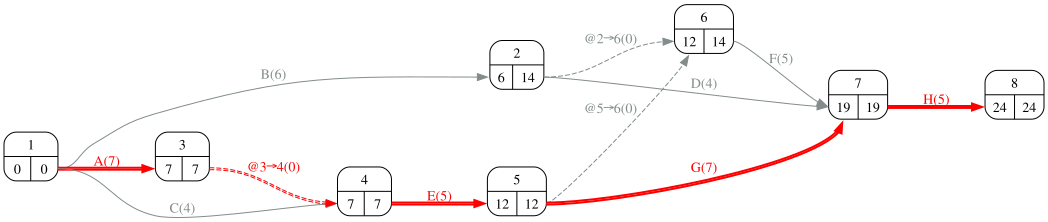

In [10]:
#| fig-cap: "Grafo PERT con duraciones medias y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [11]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(datos_proyecto['duration'], datos_proyecto['variance'])
plazo = duracion_media + 2
p_normal = float(norm.cdf((plazo - duracion_media) / desviacion_proyecto)) if desviacion_proyecto > 0 else 1.0
Markdown(f'Duración media {duracion_media}, σ = {desviacion_proyecto:.3f}; P(T ≤ {plazo}) = {p_normal:.3f} por la aproximación normal.')

Duración media 24, σ = 1.000; P(T ≤ 26) = 0.977 por la aproximación normal.

## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Simule el proyecto con 20 000 réplicas usando la distribución de cada actividad (las fijas no varían). Compare media, desviación típica y la probabilidad anterior.  

`monte_carlo` acepta una distribución por actividad: `('normal', μ, σ)`, `('triangular', a, m, b)`, `('uniform', a, b)` o una función; una duración fija es una función que siempre devuelve el mismo valor.

In [13]:
dists = {}
for act, fila in distribuciones.iterrows():
    p = parametros(fila['parametros'])
    if fila['distribucion'] == 'normal':
        dists[act] = ('normal', p[0], p[1])
    elif fila['distribucion'] == 'triangular':
        dists[act] = ('triangular', p[0], p[1], p[2])
    elif fila['distribucion'] == 'uniforme':
        dists[act] = ('uniform', p[0], p[1])
    else:
        dists[act] = (lambda valor: (lambda size=None: np.full(size, valor) if size else valor))(p[0])
resultado = proyecto.monte_carlo(dists, n_samples=20000, seed=11)
p_mc = float((resultado.tau_samples <= plazo).mean())
display(resultado.summary().round(2))
pd.DataFrame({'aproximación normal': [duracion_media, desviacion_proyecto, p_normal], 'Monte Carlo': [resultado.tau_mean, resultado.tau_std, p_mc]},
             index=['media', 'desviación típica', f'P(T ≤ {plazo})']).round(3)

,mean,std,q05,q50,q95,min,max
τ,24.02,0.99,22.39,24.02,25.66,20.66,27.3


,aproximación normal,Monte Carlo
media,24.000,24.017
desviación típica,1.000,0.993
P(T ≤ 26),0.977,0.980


## Apartado 4

In [14]:
display(Markdown(pregunta_4))

4. ¿Qué actividad tiene mayor índice de criticidad sin ser crítica en media? ¿Influye en ello que alguna actividad sea de duración fija?  

In [15]:
calendario = proyecto.calendar(datos_proyecto['duration'])
crit = (resultado.sensitivity_mean * 100).round(1).rename('índice de criticidad (%)')
tabla = pd.concat([crit, calendario['H_total'].rename('holgura'), resumen['distribución'], resumen['varianza'].astype(float).round(2)], axis=1).sort_values('índice de criticidad (%)', ascending=False)
tabla

,índice de criticidad (%),holgura,distribución,varianza
A,100.0,0,fija,0.00
E,100.0,0,triangular,0.17
H,100.0,0,triangular,0.67
G,95.7,0,triangular,0.17
F,4.3,2,uniforme,1.33
D,0.0,9,normal,0.25
B,0.0,8,triangular,0.17
C,0.0,3,triangular,0.17


In [16]:
vigilar = tabla[tabla['holgura'] > 0]['índice de criticidad (%)'].idxmax()
Markdown(f'''La actividad no crítica con mayor índice de criticidad es {vigilar} ({tabla.loc[vigilar, "índice de criticidad (%)"]} %). Las actividades de duración fija nunca cambian de ruta por sí mismas: su índice depende sólo de lo que hagan las demás; una ruta con muchas actividades fijas tiene poca varianza y rara vez «adelanta» a la crítica.''')

La actividad no crítica con mayor índice de criticidad es F (4.3 %). Las actividades de duración fija nunca cambian de ruta por sí mismas: su índice depende sólo de lo que hagan las demás; una ruta con muchas actividades fijas tiene poca varianza y rara vez «adelanta» a la crítica.